<a href="https://colab.research.google.com/github/mswargwani/ANN-Classification-Churn/blob/main/Stock_Prediction_Pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install numpy pandas matplotlib yfinance scikit-learn torch


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

import torch
import torch.nn as nn
from torch.optim import Adam

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
device

device(type='cpu')

In [24]:
ticker = 'AAPL'
df = yf.download(ticker, '2026-01-01')
# Flatten MultiIndex columns if present
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)
# Save pristine copy of unscaled close prices
df['Close_Unscaled'] = df['Close'].copy()

/tmp/ipykernel_1892/1835299350.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, '2026-01-01')
[*********************100%***********************]  1 of 1 completed


In [6]:
df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2026-01-02,270.274353,277.085800,268.269799,271.520960,37838100
2026-01-05,266.534546,270.773009,265.417591,269.905376,45647200
2026-01-06,261.647766,266.823679,261.408427,266.275185,52352100
2026-01-07,259.623322,262.964234,259.104744,262.485556,48309800
2026-01-08,258.336853,258.586174,255.005908,256.322317,50419300
...,...,...,...,...,...
2026-10-26,343.910004,347.089996,341.029999,343.920013,42743600
2026-10-27,347.100006,347.779999,342.390015,343.170013,39984400


<Axes: xlabel='Date'>

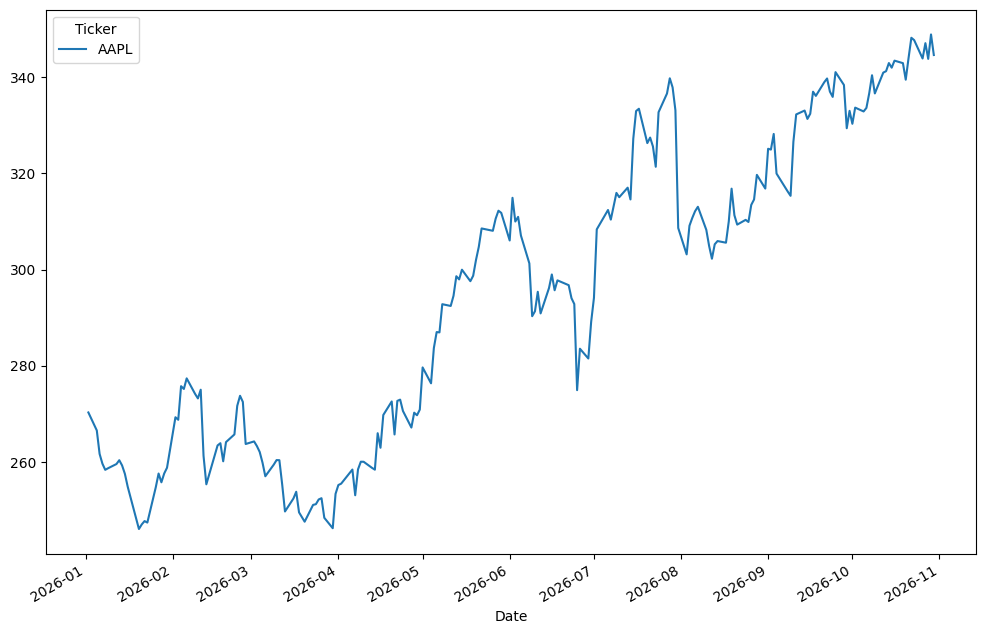

In [9]:
df.Close.plot(figsize= (12,8))

In [25]:
close_scaler = StandardScaler()
df['Close'] = close_scaler.fit_transform(df[['Close']])

### 1. Feature Preprocessing Pipeline
We will scale the remaining columns (`Open`, `High`, `Low`, `Volume`) to normalize all inputs for our PyTorch neural network.

In [20]:
# Scale the other input features using distinct scalers to prevent state overwrite
features_to_scale = ['Open', 'High', 'Low', 'Volume']
for col in features_to_scale:
    col_scaler = StandardScaler()
    df[col] = col_scaler.fit_transform(df[[col]])

# Display scaled data
display(df.head())

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2026-01-02,-0.781190,-0.658729,-0.747239,-0.736295,-0.486399
2026-01-05,-0.900430,-0.859446,-0.839142,-0.788263,-0.123766
2026-01-06,-1.056239,-0.985016,-0.968324,-0.905035,0.187592
2026-01-07,-1.120787,-1.107729,-1.042553,-1.026935,-0.000122
2026-01-08,-1.161804,-1.246930,-1.174624,-1.225187,0.097838


### 2. Time-Series Windowing & Data Split
We will convert the DataFrame into sliding window sequences (e.g., using the past 10 days of scaled data to predict the next day's price) and split the data into Training and Testing sets.

In [15]:
def create_sequences(data, sequence_length):
    X, y = [], []
    for i in range(len(data) - sequence_length):
        X.append(data[i:(i + sequence_length)])
        y.append(data[i + sequence_length, 0]) # Index 0 represents the 'Close' column
    return np.array(X), np.array(y)

# Convert scaled dataframe to numpy array
# Order of features: Close, Open, High, Low, Volume
feature_cols = ['Close', 'Open', 'High', 'Low', 'Volume']
data_arr = df[feature_cols].values

# Define hyperparameter sequence length
SEQUENCE_LENGTH = 10

X, y = create_sequences(data_arr, SEQUENCE_LENGTH)

# Split into train (80%) and test (20%) sets chronologically
split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# Convert to PyTorch Tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1).to(device)
X_test_t = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test_t = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1).to(device)

print(f"Training set shape: {X_train_t.shape}")
print(f"Testing set shape: {X_test_t.shape}")

Training set shape: torch.Size([159, 10, 5])
Testing set shape: torch.Size([40, 10, 5])


### 3. Build LSTM Neural Network
We define our dynamic PyTorch LSTMRegressor class for predictive time-series modeling.

In [16]:
class LSTMRegressor(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers=2, output_dim=1):
        super(LSTMRegressor, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # LSTM layer
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True, dropout=0.2)

        # Fully connected layer
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)

        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])  # Take output of last time step
        return out

# Model hyperparameters
INPUT_DIM = len(feature_cols)
HIDDEN_DIM = 64
NUM_LAYERS = 2

model = LSTMRegressor(INPUT_DIM, HIDDEN_DIM, NUM_LAYERS).to(device)
criterion = nn.MSELoss()
optimizer = Adam(model.parameters(), lr=0.005)

### 4. Training Loop
We optimize the model coefficients over multiple epochs.

In [17]:
epochs = 100
model.train()

for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

Epoch [10/100], Loss: 0.1568
Epoch [20/100], Loss: 0.0677
Epoch [30/100], Loss: 0.0539
Epoch [40/100], Loss: 0.0467
Epoch [50/100], Loss: 0.0396
Epoch [60/100], Loss: 0.0332
Epoch [70/100], Loss: 0.0325
Epoch [80/100], Loss: 0.0288
Epoch [90/100], Loss: 0.0301
Epoch [100/100], Loss: 0.0299


### 5. Prediction, Inverse Transform & Evaluation
Next, we make predictions, invert the scaling transformation back to real USD stock value, plot the outcomes, and evaluate using the RMSE metric.


Root Mean Squared Error (RMSE): $6.95


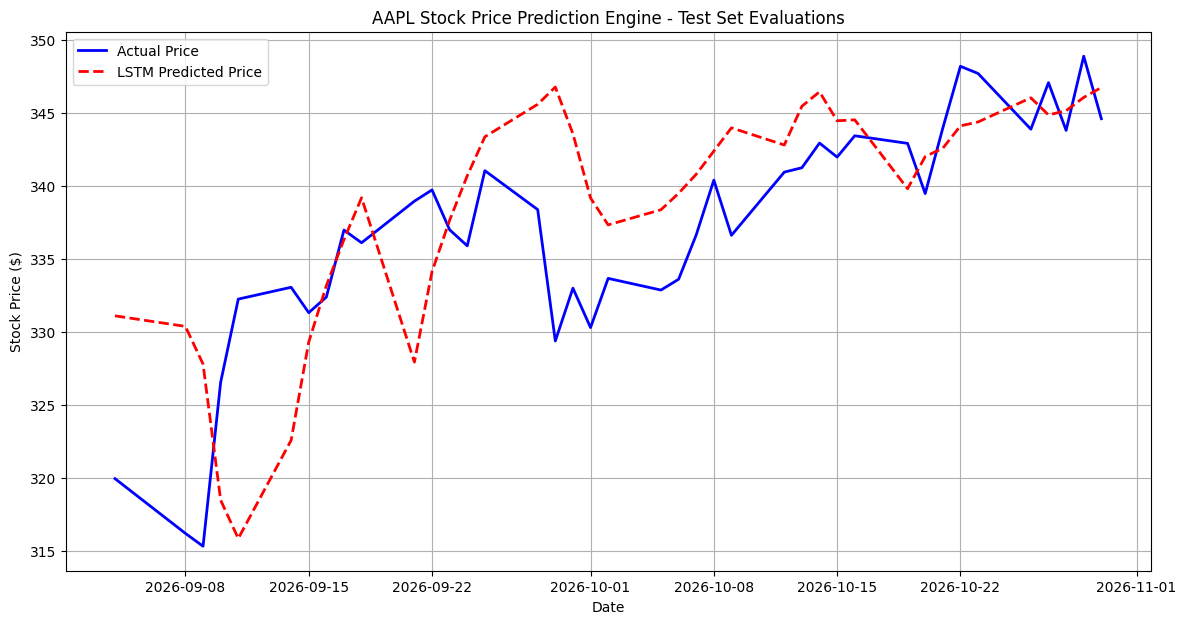

In [26]:
model.eval()
with torch.no_grad():
    predictions = model(X_test_t).cpu().numpy()

# Retrieve actual unscaled prices directly from our preserved column
y_test_unscaled = df['Close_Unscaled'].values[split_idx + SEQUENCE_LENGTH:].reshape(-1, 1)
predictions_unscaled = close_scaler.inverse_transform(predictions)

# Evaluate accuracy using RMSE in real dollars ($)
rmse = root_mean_squared_error(y_test_unscaled, predictions_unscaled)
print(f"\nRoot Mean Squared Error (RMSE): ${rmse:.2f}")

# Visualize Predictions vs Actual Price in USD
plt.figure(figsize=(14, 7))
plt.plot(df.index[split_idx + SEQUENCE_LENGTH:], y_test_unscaled, label='Actual Price', color='blue', linewidth=2)
plt.plot(df.index[split_idx + SEQUENCE_LENGTH:], predictions_unscaled, label='LSTM Predicted Price', color='red', linestyle='--', linewidth=2)
plt.title(f'{ticker} Stock Price Prediction Engine - Test Set Evaluations')
plt.xlabel('Date')
plt.ylabel('Stock Price ($)')
plt.legend()
plt.grid(True)
plt.show()

In [27]:
# Calculate Mean Absolute Percentage Error (MAPE)
mape = np.mean(np.abs((y_test_unscaled - predictions_unscaled) / y_test_unscaled)) * 100

# Define percentage accuracy
accuracy_pct = 100 - mape

# Calculate maximum percentage error to understand worst-case scenarios
max_error_pct = np.max(np.abs((y_test_unscaled - predictions_unscaled) / y_test_unscaled)) * 100

print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"Average Forecast Accuracy: {accuracy_pct:.2f}%")
print(f"Maximum Prediction Error: {max_error_pct:.2f}%")

Mean Absolute Percentage Error (MAPE): 1.61%
Average Forecast Accuracy: 98.39%
Maximum Prediction Error: 5.28%
